# Storyboard sequence generation


In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_DIR = Path('/content/drive/MyDrive/project')
PANEL_DIR = PROJECT_DIR / 'panels'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'controlnet_batch_csa_off'

seq_name = 'seq02'
out_dir = OUTPUT_DIR / seq_name

print(f"Panel directory: {PANEL_DIR}")
print(f"Reading saved sequence from: {out_dir}")

Panel directory: /content/drive/MyDrive/project/panels
Reading saved sequence from: /content/drive/MyDrive/project/outputs/controlnet_batch_csa_off/seq02


In [25]:
import os

# 1. Resolve and check the panels folder
panels_dir = Path(PANEL_DIR)
if not panels_dir.is_dir():
    raise FileNotFoundError(f"Panels folder not found: {panels_dir}")

# 2. Collect and sort image files (e.g., png, jpg, jpeg)
valid_extensions = {'.png', '.jpg', '.jpeg', '.webp'}
img_files = sorted([f for f in panels_dir.iterdir() if f.suffix.lower() in valid_extensions])
print(f"Found {len(img_files)} panel images in {panels_dir}")

# 3. Load original images
originals = []
for f in img_files:
    try:
        img = Image.open(f).convert('RGB')
        originals.append(img)
    except Exception as e:
        print(f"Warning: Failed to load {f.name} - {e}")
        originals.append(None)

# 4. Correct panel_paths to match the actual list of paths for the plotting code
panel_paths = [str(f) for f in img_files]

# 5. Initialize placeholders for frames and statuses (to match the originals for display purposes)
# Replace these placeholders with your actual frame sequences and generation status lists later
frames = [Image.new('RGB', (100, 100), color='gray') for _ in originals]
statuses = ['Placeholder' for _ in originals]


Found 16 panel images in /content/drive/MyDrive/project/panels


In [26]:
# Load actual generated frames and metadata from out_dir
from pathlib import Path
import json

print(f"Scanning directory: {out_dir}")

# Match only the generated panel images (e.g., panel01.png, panel02.png, ...)
frame_files = sorted([
    f for f in Path(out_dir).iterdir()
    if f.name.startswith("panel") and f.suffix.lower() in {'.png', '.jpg', '.jpeg', '.webp'}
    and "_cond" not in f.name
])

real_frames = []
real_statuses = []

for i, panel_path in enumerate(panel_paths):
    if i < len(frame_files):
        try:
            img_path = frame_files[i]
            img = Image.open(img_path).convert('RGB')
            real_frames.append(img)
            real_statuses.append("Generated")
            print(f"Loaded frame {i+1}: {img_path.name}")
        except Exception as e:
            real_frames.append(Image.new('RGB', (100, 100), color='red'))
            real_statuses.append("Error loading")
    else:
        real_frames.append(Image.new('RGB', (100, 100), color='gray'))
        real_statuses.append("Missing")

# Update active variables used by the display cell
frames = real_frames
statuses = real_statuses

Scanning directory: /content/drive/MyDrive/project/outputs/controlnet_batch_csa_off/seq02
Loaded frame 1: panel01.png
Loaded frame 2: panel02.png
Loaded frame 3: panel03.png
Loaded frame 4: panel04.png
Loaded frame 5: panel05.png
Loaded frame 6: panel06.png


In [27]:
import os
import glob

# --- Define a sequence: same character described the same way in every prompt ---
panel_files = sorted(glob.glob(os.path.join(PANEL_DIR, f'{seq_name}_panel*.png')))
CHAR_A_DESC = "blonde boy wearing a blue shirt and white rounded hood"
CHAR_B_DESC = "simple yellow round bulldog with big eyes"
SETTING = "bedroom"

# 6 panels
actions = [
    f"{CHAR_A_DESC} sitting in a bed and talking with pointing a finger",
    f"{CHAR_B_DESC} sitting on the floor looking up",
    f"{CHAR_B_DESC} leans back on a pillow on the floor",
    f"{CHAR_A_DESC} looking scared with wide eyes while {CHAR_B_DESC} is leaning back",
    f"{CHAR_B_DESC} still leaning back and picks up a part of a donut",
    f"{CHAR_B_DESC} holding a part of a donut near their mouth"
][:len(panel_files)]

prompts_2 = [f"{a}, {SETTING}" for a in actions]

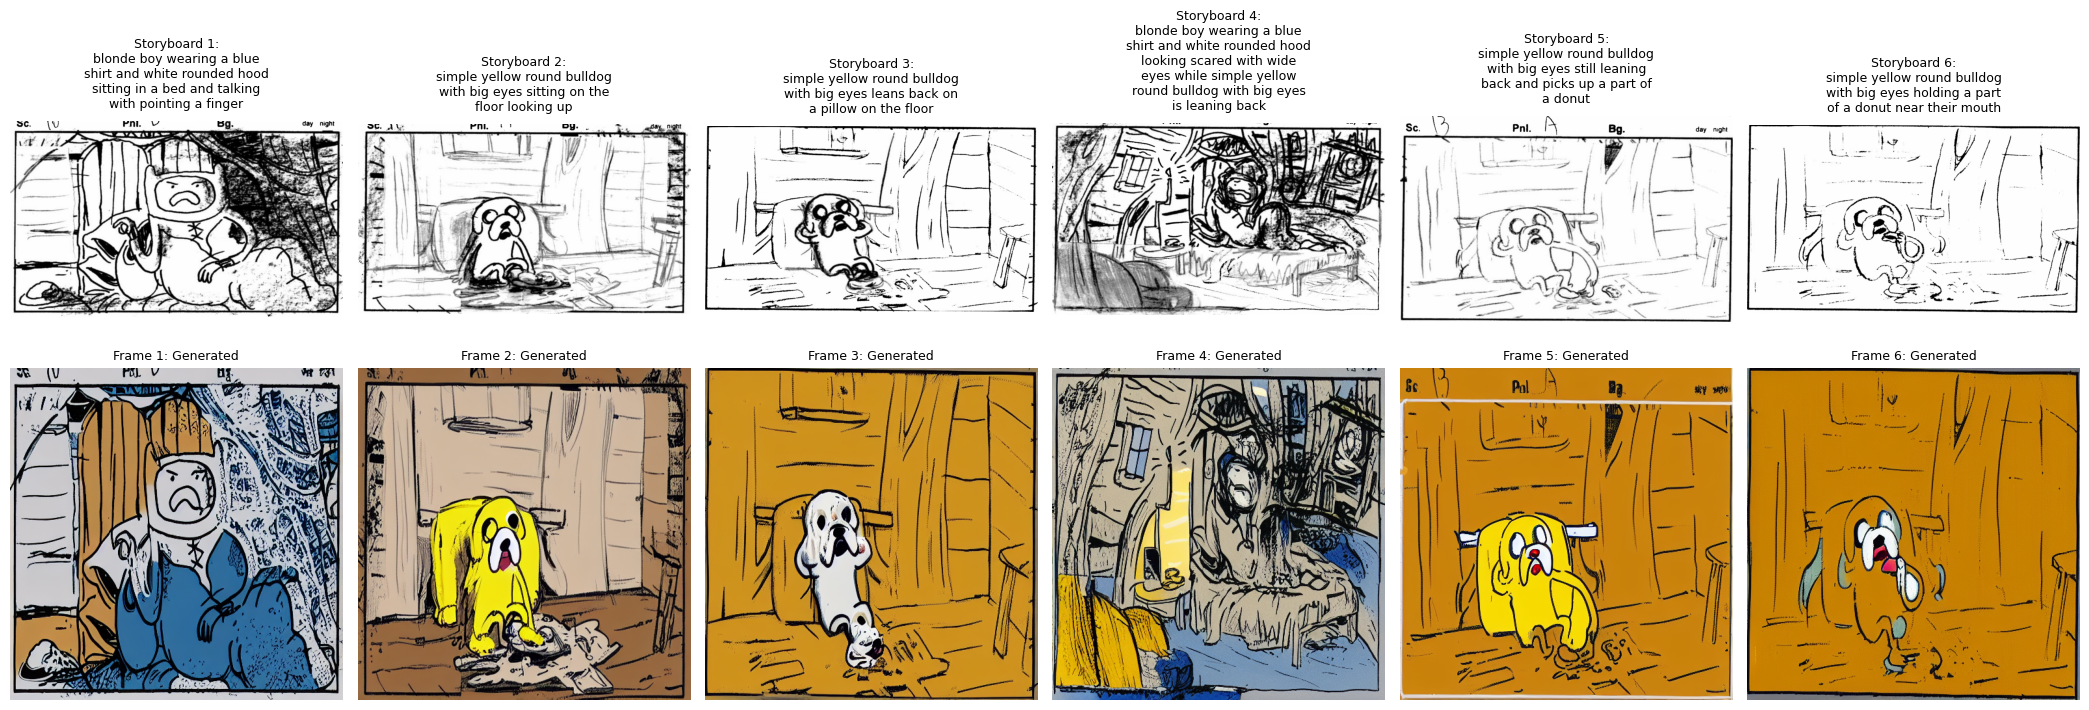

In [28]:
import textwrap

# Filter to only keep the 6 panels corresponding to seq02
num_seq02_panels = 6
seq02_originals = originals[6:12] if len(originals) >= 12 else originals[:num_seq02_panels]
seq02_frames = frames[:num_seq02_panels]
seq02_statuses = statuses[:num_seq02_panels]

fig, axes = plt.subplots(2, num_seq02_panels, figsize=(3.5 * num_seq02_panels, 7.5))

if num_seq02_panels == 1:
    axes = axes.reshape(2, 1)

for column, (original, frame, status) in enumerate(zip(seq02_originals, seq02_frames, seq02_statuses)):
    # Get matching action/prompt description if available
    action_desc = ""
    if column < len(actions):
        action_desc = actions[column]

    wrapped_title = "\n".join(textwrap.wrap(action_desc, width=28))

    if original is not None:
        axes[0, column].imshow(original)
    else:
        axes[0, column].text(0.5, 0.5, 'Panel unreadable', ha='center', va='center')

    axes[0, column].set_title(f'Storyboard {column + 1}:\n{wrapped_title}', fontsize=9, pad=10)
    axes[1, column].imshow(frame)
    axes[1, column].set_title(f'Frame {column + 1}: {status}', fontsize=9)

    axes[0, column].axis('off')
    axes[1, column].axis('off')

plt.tight_layout()
plt.show()

In [29]:
import json
import os

# Correct path is directly in the local Colab directory
notebook_path = '/content/drive/MyDrive/project/character_crop.ipynb'

with open(notebook_path, 'r', encoding='utf-8') as f:
    nb_data = json.load(f)

# Print the code cells to understand what needs to be integrated
for i, cell in enumerate(nb_data.get('cells', [])):
    if cell.get('cell_type') == 'code':
        print(f"--- Code Cell {i+1} ---")
        print("".join(cell.get('source', [])))
        print("\n")

--- Code Cell 1 ---
from pathlib import Path
from typing import Protocol, TypeAlias

from PIL import Image

import torch

from transformers import (
    AutoProcessor,
    Florence2ForConditionalGeneration,
)

from transformers import Sam2Model, Sam2Processor


BBox: TypeAlias = tuple[int, int, int, int]


--- Code Cell 2 ---
class CharacterLocator(Protocol):
    """Locates a requested character within an image."""

    def locate(
        self,
        image: Image.Image,
        prompt: str,
    ) -> BBox:
        """
        Locate a character and return its bounding box.

        Args:
            image: Source image.
            prompt: Character description such as "the vampire".

        Returns:
            Bounding box as (left, top, right, bottom).
        """
        ...


--- Code Cell 3 ---
class CharacterSegmenter(Protocol):
    """Segments a character using a supplied bounding box."""

    def segment(
        self,
        image: Image.Image,
        bbox: BBox,
    ) -

In [30]:
# Read all code from character_crop.ipynb and compile them sequentially
import json

with open(notebook_path, 'r', encoding='utf-8') as f:
    nb_data = json.load(f)

# Combine all code cells from 1 to 8 (definition cells)
combined_code_lines = []
for i, cell in enumerate(nb_data.get('cells', [])):
    # Skip initialization / demo cells (cells 9, 10, 11, 12, 13)
    if cell.get('cell_type') == 'code' and i < 8:
        combined_code_lines.extend(cell.get('source', []))
        combined_code_lines.append('\n\n')

combined_code = "".join(combined_code_lines)

# We will write this content directly to a new file, then load or print it,
# but since we want to run and make it available in the notebook:
exec(combined_code)
print("Successfully imported and executed all classes/functions from character_crop.ipynb:")
print("- CharacterLocator, Florence2CharacterLocator")
print("- CharacterSegmenter, SAM2CharacterSegmenter")
print("- BackgroundStrategy, TransparentBackgroundStrategy, SolidBackgroundStrategy")
print("- CharacterReferenceExtractor")

Successfully imported and executed all classes/functions from character_crop.ipynb:
- CharacterLocator, Florence2CharacterLocator
- CharacterSegmenter, SAM2CharacterSegmenter
- BackgroundStrategy, TransparentBackgroundStrategy, SolidBackgroundStrategy
- CharacterReferenceExtractor


In [31]:
import logging
from typing import Union, List, Dict, Optional, Tuple, Any

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import numpy as np

# Configure Logger
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("IdentityStabilityEvaluator")

class IdentityStabilityEvaluator:
    """
    Computes Inter-Frame Identity Stability across a sequence of generated character frames
    using deep features extracted from Meta's DINOv2 models.

    Isolates character identity by cropping to bounding boxes from provided binary masks,
    masks out non-character pixels to prevent background leakage, and extracts normalized embeddings.
    """
    def __init__(
        self,
        model_size: str = "vitb14",
        device: Optional[str] = None,
        drift_threshold: float = 0.70,
        padding_color: int = 0  # 0 for Black padding
    ) -> None:
        """
        Initializes the evaluation pipeline by loading the DINOv2 feature extractor.

        Args:
            model_size: Scale of the DINOv2 model to pull ('vitb14' or 'vitl14').
            device: Execution device. Defaults to auto-select (CUDA if available).
            drift_threshold: Cut-off cosine similarity threshold to trigger drift alerts.
            padding_color: RGB value (0-255) for background padding pixels.
        """
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.drift_threshold = drift_threshold
        self.padding_color = padding_color

        repo = "facebookresearch/dinov2"
        model_name = f"dinov2_{model_size}"
        logger.info(f"Loading DINOv2 model ({model_name}) from torch.hub on {self.device}...")
        self.model = torch.hub.load(repo, model_name).to(self.device)
        self.model.eval()

        # Standard ImageNet pre-processing required by DINOv2
        self.transform = T.Compose([
            T.Resize((224, 224)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def _to_pil(self, img: Union[str, Path, Image.Image, torch.Tensor]) -> Image.Image:
        """Helper to load or convert any image inputs into standard PIL RGB Format."""
        if isinstance(img, (str, Path)):
            return Image.open(img).convert("RGB")
        elif isinstance(img, torch.Tensor):
            # Expected [C, H, W]
            img_np = img.mul(255).byte().cpu().numpy().transpose(1, 2, 0)
            return Image.fromarray(img_np).convert("RGB")
        elif isinstance(img, Image.Image):
            return img.convert("RGB")
        else:
            raise TypeError(f"Unsupported image input type: {type(img)}")

    def _preprocess_character_region(
        self,
        frame: Image.Image,
        mask: Optional[Image.Image]
    ) -> Tuple[Optional[torch.Tensor], bool]:
        """
        Extracts the character from the frame by cropping it to the mask's
        bounding box and masking out the non-character background.

        Returns:
            Processed image tensor or None if the frame/mask is blank/invalid.
            Boolean indicating if the frame failed validation.
        """
        # Check for blank / empty physical inputs
        img_np = np.array(frame)
        if img_np.mean() < 5:
            return None, True

        if mask is None:
            # If no mask, fallback to entire frame
            masked_img = frame
        else:
            mask_gray = mask.convert("L")
            mask_np = np.array(mask_gray)

            if mask_np.sum() == 0:
                return None, True

            # Apply mask to keep character and fill back with self.padding_color
            background = Image.new("RGB", frame.size, color=(self.padding_color, self.padding_color, self.padding_color))
            masked_img = Image.composite(frame, background, mask_gray)

            # Obtain bounding box coordinates of character to crop tightly
            bbox = mask_gray.getbbox()
            if bbox:
                masked_img = masked_img.crop(bbox)

        # Prepare for Vision Transformer
        tensor_img = self.transform(masked_img).unsqueeze(0).to(self.device)
        return tensor_img, False

    @torch.no_grad()
    def get_embedding(self, tensor_img: torch.Tensor) -> torch.Tensor:
        """Extracts and L2-normalizes the DINOv2 CLS feature embedding vector."""
        features = self.model(tensor_img)
        normalized_features = F.normalize(features, p=2, dim=1)
        return normalized_features.squeeze(0)

    def evaluate_sequence(
        self,
        frames: List[Union[str, Path, Image.Image, torch.Tensor]],
        masks: List[Optional[Image.Image]],
        reference_image: Optional[Union[str, Path, Image.Image, torch.Tensor]] = None
    ) -> Dict[str, Any]:
        """
        Evaluates inter-frame stability of identity sequences.
        """
        num_frames = len(frames)
        embeddings: Dict[int, torch.Tensor] = {}
        failed_indices: List[int] = []

        # 1. Process active frames & compile valid character embeddings
        for idx in range(num_frames):
            try:
                pil_frame = self._to_pil(frames[idx])
                pil_mask = masks[idx] if idx < len(masks) else None

                char_tensor, is_failed = self._preprocess_character_region(pil_frame, pil_mask)
                if is_failed or char_tensor is None:
                    logger.warning(f"Frame {idx} marked as blank or character missing! Skipping.")
                    failed_indices.append(idx)
                    continue

                embeddings[idx] = self.get_embedding(char_tensor)
            except Exception as e:
                logger.error(f"Error processing frame index {idx}: {e}")
                failed_indices.append(idx)

        # 2. Reference Image embedding extraction
        ref_embedding: Optional[torch.Tensor] = None
        if reference_image is not None:
            try:
                ref_pil = self._to_pil(reference_image)
                ref_tensor, ref_failed = self._preprocess_character_region(ref_pil, None)
                if not ref_failed and ref_tensor is not None:
                    ref_embedding = self.get_embedding(ref_tensor)
            except Exception as e:
                logger.error(f"Failed to process Reference Image: {e}")

        # 3. Compute Metrics
        consecutive_scores: List[float] = []
        drift_detected = False

        # Sort active frames indices
        active_indices = sorted(list(embeddings.keys()))

        # Compute consecutive frame transition metrics
        for i in range(len(active_indices) - 1):
            idx1, idx2 = active_indices[i], active_indices[i+1]
            sim = torch.dot(embeddings[idx1], embeddings[idx2]).item()
            consecutive_scores.append(float(sim))
            if sim < self.drift_threshold:
                drift_detected = True

        mean_consecutive = float(np.mean(consecutive_scores)) if consecutive_scores else 0.0

        # Compute full sequence pairwise correlation matrices and off-diagonal summaries
        all_pairs_sim: List[float] = []
        for idx_i in active_indices:
            for idx_j in active_indices:
                if idx_i < idx_j:
                    sim = torch.dot(embeddings[idx_i], embeddings[idx_j]).item()
                    all_pairs_sim.append(float(sim))

        global_pairwise = float(np.mean(all_pairs_sim)) if all_pairs_sim else 0.0

        # Compute reference fidelity scores
        reference_scores: Optional[List[float]] = None
        if ref_embedding is not None:
            reference_scores = []
            for idx in range(num_frames):
                if idx in embeddings:
                    sim = torch.dot(embeddings[idx], ref_embedding).item()
                    reference_scores.append(float(sim))
                else:
                    reference_scores.append(0.0) # Masked/failed marker placeholder value

        return {
            "consecutive_scores": consecutive_scores,
            "mean_consecutive_similarity": mean_consecutive,
            "global_pairwise_similarity": global_pairwise,
            "reference_fidelity_scores": reference_scores,
            "drift_detected": drift_detected,
            "failed_frames": failed_indices
        }

if __name__ == "__main__":
    # Executable sample module walkthrough verification
    print("--- Executing IdentityStabilityEvaluator Verification Block ---")
    evaluator = IdentityStabilityEvaluator(model_size="vitb14")

    # Generate simulated images to demonstrate pipeline robustness
    mock_image_1 = Image.new("RGB", (300, 300), color=(180, 50, 50))  # red character blob
    mock_mask_1 = Image.new("L", (300, 300), color=0)
    ImageDraw = Image.new("L", (300, 300))
    # Create character masked active area inside mask
    mock_mask_1.paste(255, [50, 50, 250, 250])

    mock_image_2 = Image.new("RGB", (300, 300), color=(170, 50, 50))  # adjacent consistent panel
    mock_mask_2 = mock_mask_1.copy()

    mock_image_3 = Image.new("RGB", (300, 300), color=(0, 0, 0))      # simulated blank/black frame failure
    mock_mask_3 = Image.new("L", (300, 300), color=0)

    mock_reference = Image.new("RGB", (300, 300), color=(190, 45, 45))

    frames_sequence = [mock_image_1, mock_image_2, mock_image_3]
    masks_sequence = [mock_mask_1, mock_mask_2, mock_mask_3]

    # Compute and display analytical summary output dict
    summary = evaluator.evaluate_sequence(
        frames=frames_sequence,
        masks=masks_sequence,
        reference_image=mock_reference
    )

    print("\nSummary Metric Dictionary:")
    for k, v in summary.items():
        print(f"{k}: {v}")


--- Executing IdentityStabilityEvaluator Verification Block ---


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main



Summary Metric Dictionary:
consecutive_scores: [0.9992502927780151]
mean_consecutive_similarity: 0.9992502927780151
global_pairwise_similarity: 0.9992502927780151
reference_fidelity_scores: [0.9975199699401855, 0.9941680431365967, 0.0]
drift_detected: False
failed_frames: [2]


Initializing Florence-2 and SAM 2 for character extraction...


Loading weights:   0%|          | 0/665 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Processing generated sequence frames...


<string>:366: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


Frame 1: Character extracted successfully.
Frame 2: Character extracted successfully.
Frame 3: Character extracted successfully.
Frame 4: Character extracted successfully.
Frame 5: Character extracted successfully.
Frame 6: Character extracted successfully.


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main



=== IDENTITY STABILITY METRICS ===
Global Sequence Stability Index (Mean Pairwise Similarity): 0.4675
Mean Consecutive Similarity: 0.4395
Drift Detected: True

Consecutive Scene-to-Scene Similarity Scores:
  Frame 1 -> Frame 2: 0.2927
  Frame 2 -> Frame 3: 0.6470
  Frame 3 -> Frame 4: 0.1822
  Frame 4 -> Frame 5: 0.3681
  Frame 5 -> Frame 6: 0.7075


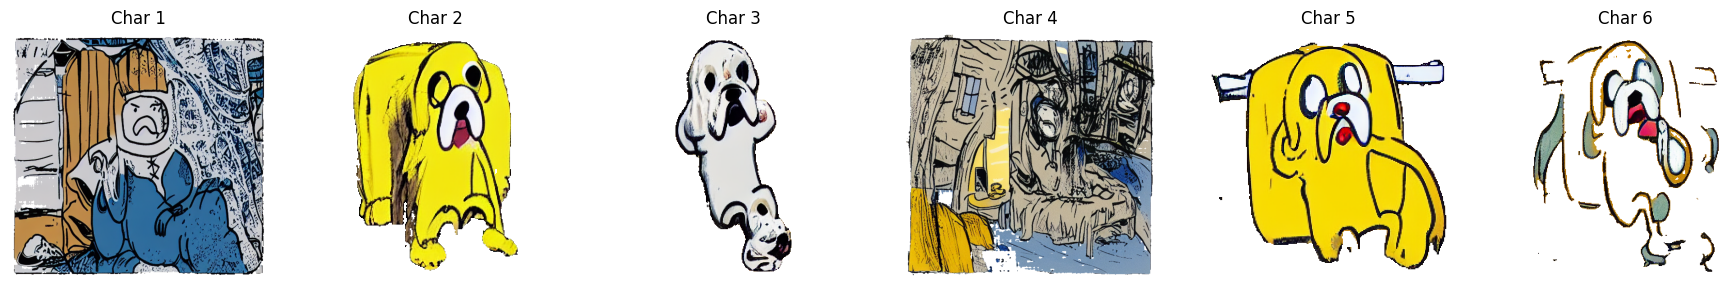

In [32]:
# Filter to only keep the 6 panels corresponding to seq02
seq02_frames = frames[:6]

# 1. Initialize character extraction components
print("Initializing Florence-2 and SAM 2 for character extraction...")
locator = Florence2CharacterLocator()
segmenter = SAM2CharacterSegmenter()
extractor = CharacterReferenceExtractor(
    locator=locator,
    segmenter=segmenter,
    background_strategy=TransparentBackgroundStrategy(),
    padding=10,
)

# 2. Extract masks and cropped character images from our generated frames
character_images = []
character_masks = []

print("Processing generated sequence frames...")
for idx, frame_img in enumerate(seq02_frames):
    try:
        # Locate and segment "the vampire"
        bbox = locator.locate(frame_img, "the vampire")
        mask = segmenter.segment(frame_img, bbox)

        # Save crop & mask
        character_masks.append(mask)

        # Extract isolated character image
        cropped_char = extractor.extract(frame_img, "the vampire")
        character_images.append(cropped_char)
        print(f"Frame {idx+1}: Character extracted successfully.")
    except Exception as e:
        print(f"Frame {idx+1}: Extraction failed or character not found. {e}")
        character_masks.append(None)
        character_images.append(None)

# 3. Evaluate identity stability across the sequence
evaluator = IdentityStabilityEvaluator(model_size="vitb14")
evaluation_results = evaluator.evaluate_sequence(
    frames=seq02_frames,
    masks=character_masks
)

# 4. Show the extracted character sequence and print calculated scores
print("\n=== IDENTITY STABILITY METRICS ===")
print(f"Global Sequence Stability Index (Mean Pairwise Similarity): {evaluation_results['global_pairwise_similarity']:.4f}")
print(f"Mean Consecutive Similarity: {evaluation_results['mean_consecutive_similarity']:.4f}")
print(f"Drift Detected: {evaluation_results['drift_detected']}")
if evaluation_results['failed_frames']:
    print(f"Failed/Skipped Frames: {evaluation_results['failed_frames']}")

print("\nConsecutive Scene-to-Scene Similarity Scores:")
for i, score in enumerate(evaluation_results['consecutive_scores']):
    print(f"  Frame {i+1} -> Frame {i+2}: {score:.4f}")

# Plot the segmented character crops (specifically for seq02_frames)
fig, axes = plt.subplots(1, len(seq02_frames), figsize=(3 * len(seq02_frames), 3))
if len(seq02_frames) == 1:
    axes = [axes]

for i, char_img in enumerate(character_images):
    if char_img is not None:
        axes[i].imshow(char_img)
        axes[i].set_title(f"Char {i+1}")
    else:
        axes[i].text(0.5, 0.5, "N/A", ha='center', va='center')
        axes[i].set_title(f"Frame {i+1} (Failed)")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

               IDENTITY STABILITY RESULTS                 
Total Sequence Stability Score (Global Mean): 0.4675
Mean Consecutive Step Similarity:            0.4395
-----------------------------------------------------------
Consecutive Scene-to-Scene Similarity Scores:
  Scene 1 -> Scene 2: 0.2927
  Scene 2 -> Scene 3: 0.6470
  Scene 3 -> Scene 4: 0.1822
  Scene 4 -> Scene 5: 0.3681
  Scene 5 -> Scene 6: 0.7075



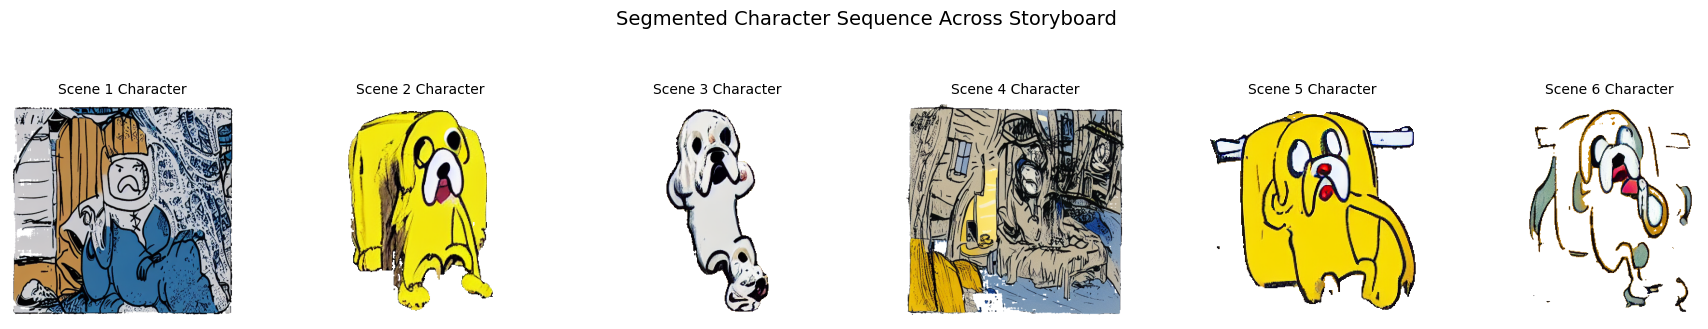

In [33]:
seq02_character_images = character_images[:6]
consecutive_scores = evaluation_results.get('consecutive_scores', [])[:5]
global_score = evaluation_results.get('global_pairwise_similarity', 0.0)
mean_consecutive = evaluation_results.get('mean_consecutive_similarity', 0.0)

print("===========================================================")
print("               IDENTITY STABILITY RESULTS                 ")
print("===========================================================")
print(f"Total Sequence Stability Score (Global Mean): {global_score:.4f}")
print(f"Mean Consecutive Step Similarity:            {mean_consecutive:.4f}")
print("-----------------------------------------------------------")
print("Consecutive Scene-to-Scene Similarity Scores:")
for idx, score in enumerate(consecutive_scores):
    print(f"  Scene {idx+1} -> Scene {idx+2}: {score:.4f}")
print("===========================================================\n")

# Display the 6 isolated character sequence panels
fig, axes = plt.subplots(1, len(seq02_character_images), figsize=(3 * len(seq02_character_images), 3))
if len(seq02_character_images) == 1:
    axes = [axes]

for i, char_img in enumerate(seq02_character_images):
    if char_img is not None:
        axes[i].imshow(char_img)
        axes[i].set_title(f"Scene {i+1} Character", fontsize=10)
    else:
        axes[i].text(0.5, 0.5, 'N/A\n(Missing/Failed)', ha='center', va='center', color='red')
        axes[i].set_title(f"Scene {i+1}", fontsize=10)
    axes[i].axis('off')

plt.suptitle("Segmented Character Sequence Across Storyboard", fontsize=14, y=1.08)
plt.tight_layout()
plt.show()

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main



--- Extracting and evaluating character: Finn ---
Finn is present in panels (0-based): [0, 3]


<string>:366: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


Successfully loaded and segmented reference sheet for Finn.
  Panel 1: Finn located & segmented successfully.
  Panel 4: Finn located & segmented successfully.

--- Extracting and evaluating character: Jake ---
Jake is present in panels (0-based): [1, 2, 3, 4, 5]
Successfully loaded and segmented reference sheet for Jake.
  Panel 2: Jake located & segmented successfully.
  Panel 3: Jake located & segmented successfully.
  Panel 4: Jake located & segmented successfully.
  Panel 5: Jake located & segmented successfully.
  Panel 6: Jake located & segmented successfully.

           IDENTITY STABILITY REPORT: FINN
Global Pairwise Similarity:      0.4501
Mean Consecutive Similarity:     0.4501
Mean Reference Fidelity:         0.3659
Drift Status:                    DRIFT DETECTED!
----------------------------------------------------------
Per-Panel Reference Fidelity:
  Panel 1: 0.4531
  Panel 4: 0.2788
----------------------------------------------------------
Consecutive Transitions:
  Pa

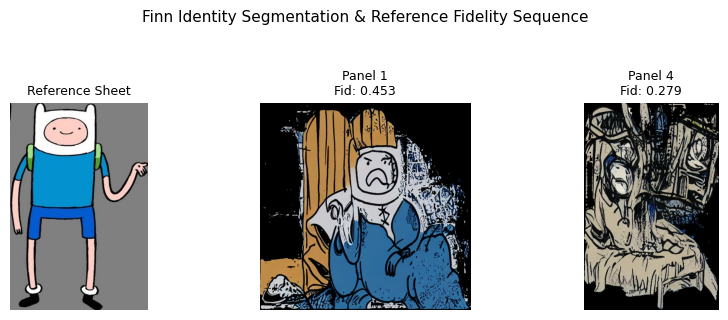


           IDENTITY STABILITY REPORT: JAKE
Global Pairwise Similarity:      0.4941
Mean Consecutive Similarity:     0.4507
Mean Reference Fidelity:         0.4158
Drift Status:                    DRIFT DETECTED!
----------------------------------------------------------
Per-Panel Reference Fidelity:
  Panel 2: 0.4213
  Panel 3: 0.3865
  Panel 4: 0.2852
  Panel 5: 0.5271
  Panel 6: 0.4589
----------------------------------------------------------
Consecutive Transitions:
  Panel 2 -> Panel 3: 0.6479
  Panel 3 -> Panel 4: 0.1843
  Panel 4 -> Panel 5: 0.3490
  Panel 5 -> Panel 6: 0.6217



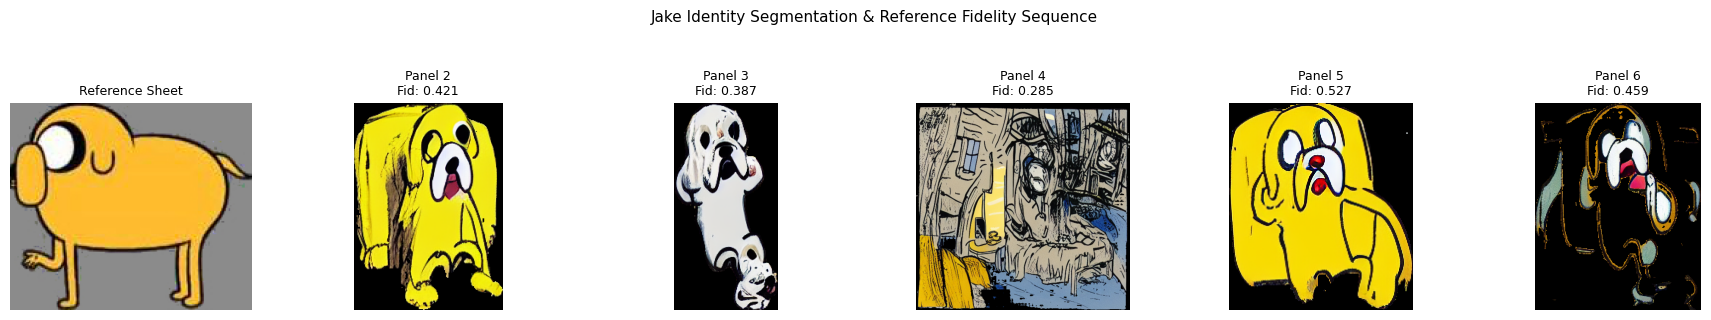

In [34]:
# ==========================================
# PART 1: Updated IdentityStabilityEvaluator
# ==========================================

import logging
from typing import Union, List, Dict, Optional, Tuple, Any
from pathlib import Path
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import numpy as np
import matplotlib.pyplot as plt

# Configure Logger
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("IdentityStabilityEvaluator")

class IdentityStabilityEvaluator:
    """
    Computes Inter-Frame Identity Stability across a sequence of generated character frames
    using deep features extracted from Meta's DINOv2 models.
    Supports reference image masking and bounding-box tight crops.
    """
    def __init__(
        self,
        model_size: str = "vitb14",
        device: Optional[str] = None,
        drift_threshold: float = 0.70,
        padding_color: int = 0  # 0 for Black padding
    ) -> None:
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.drift_threshold = drift_threshold
        self.padding_color = padding_color

        repo = "facebookresearch/dinov2"
        model_name = f"dinov2_{model_size}"
        logger.info(f"Loading DINOv2 model ({model_name}) from torch.hub on {self.device}...")
        self.model = torch.hub.load(repo, model_name).to(self.device)
        self.model.eval()

        # Standard ImageNet pre-processing required by DINOv2
        self.transform = T.Compose([
            T.Resize((224, 224)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def _to_pil(self, img: Union[str, Path, Image.Image, torch.Tensor]) -> Image.Image:
        if isinstance(img, (str, Path)):
            return Image.open(img).convert("RGB")
        elif isinstance(img, torch.Tensor):
            img_np = img.mul(255).byte().cpu().numpy().transpose(1, 2, 0)
            return Image.fromarray(img_np).convert("RGB")
        elif isinstance(img, Image.Image):
            return img.convert("RGB")
        else:
            raise TypeError(f"Unsupported image input type: {type(img)}")

    def _preprocess_character_region(
        self,
        frame: Image.Image,
        mask: Optional[Image.Image]
    ) -> Tuple[Optional[torch.Tensor], bool]:
        img_np = np.array(frame)
        if img_np.mean() < 5:
            return None, True

        if mask is None:
            masked_img = frame
        else:
            mask_gray = mask.convert("L")
            mask_np = np.array(mask_gray)

            if mask_np.sum() == 0:
                return None, True

            background = Image.new("RGB", frame.size, color=(self.padding_color, self.padding_color, self.padding_color))
            masked_img = Image.composite(frame, background, mask_gray)

            bbox = mask_gray.getbbox()
            if bbox:
                masked_img = masked_img.crop(bbox)

        tensor_img = self.transform(masked_img).unsqueeze(0).to(self.device)
        return tensor_img, False

    @torch.no_grad()
    def get_embedding(self, tensor_img: torch.Tensor) -> torch.Tensor:
        features = self.model(tensor_img)
        normalized_features = F.normalize(features, p=2, dim=1)
        return normalized_features.squeeze(0)

    def evaluate_sequence(
        self,
        frames: List[Union[str, Path, Image.Image, torch.Tensor]],
        masks: List[Optional[Image.Image]],
        reference_image: Optional[Union[str, Path, Image.Image, torch.Tensor]] = None,
        reference_mask: Optional[Image.Image] = None
    ) -> Dict[str, Any]:
        num_frames = len(frames)
        embeddings: Dict[int, torch.Tensor] = {}
        failed_indices: List[int] = []

        # 1. Process active frames
        for idx in range(num_frames):
            try:
                pil_frame = self._to_pil(frames[idx])
                pil_mask = masks[idx] if idx < len(masks) else None

                char_tensor, is_failed = self._preprocess_character_region(pil_frame, pil_mask)
                if is_failed or char_tensor is None:
                    logger.warning(f"Frame index {idx} marked as blank or character missing! Skipping.")
                    failed_indices.append(idx)
                    continue

                embeddings[idx] = self.get_embedding(char_tensor)
            except Exception as e:
                logger.error(f"Error processing frame index {idx}: {e}")
                failed_indices.append(idx)

        # 2. Reference Image embedding extraction (using optional reference mask)
        ref_embedding: Optional[torch.Tensor] = None
        if reference_image is not None:
            try:
                ref_pil = self._to_pil(reference_image)
                ref_tensor, ref_failed = self._preprocess_character_region(ref_pil, reference_mask)
                if not ref_failed and ref_tensor is not None:
                    ref_embedding = self.get_embedding(ref_tensor)
            except Exception as e:
                logger.error(f"Failed to process Reference Image: {e}")

        # 3. Compute Metrics
        consecutive_scores: List[float] = []
        drift_detected = False

        active_indices = sorted(list(embeddings.keys()))

        for i in range(len(active_indices) - 1):
            idx1, idx2 = active_indices[i], active_indices[i+1]
            sim = torch.dot(embeddings[idx1], embeddings[idx2]).item()
            consecutive_scores.append(float(sim))
            if sim < self.drift_threshold:
                drift_detected = True

        mean_consecutive = float(np.mean(consecutive_scores)) if consecutive_scores else 0.0

        all_pairs_sim: List[float] = []
        for idx_i in active_indices:
            for idx_j in active_indices:
                if idx_i < idx_j:
                    sim = torch.dot(embeddings[idx_i], embeddings[idx_j]).item()
                    all_pairs_sim.append(float(sim))

        global_pairwise = float(np.mean(all_pairs_sim)) if all_pairs_sim else 0.0

        reference_scores: Optional[List[float]] = None
        mean_ref_fidelity = 0.0
        if ref_embedding is not None:
            reference_scores = []
            valid_ref_scores = []
            for idx in range(num_frames):
                if idx in embeddings:
                    sim = torch.dot(embeddings[idx], ref_embedding).item()
                    reference_scores.append(float(sim))
                    valid_ref_scores.append(float(sim))
                else:
                    reference_scores.append(0.0)
            if valid_ref_scores:
                mean_ref_fidelity = float(np.mean(valid_ref_scores))

        return {
            "consecutive_scores": consecutive_scores,
            "mean_consecutive_similarity": mean_consecutive,
            "global_pairwise_similarity": global_pairwise,
            "reference_fidelity_scores": reference_scores,
            "mean_reference_fidelity": mean_ref_fidelity,
            "drift_detected": drift_detected,
            "failed_frames": failed_indices
        }

# ==========================================================
# PART 2: Reference Loading, Per-Character Extraction & Loop
# ==========================================================

CHAR_REF_DIR = PROJECT_DIR / 'char_refs'

# Multi-character definition
char_configs = {
    "Finn": {
        "prompt": CHAR_A_DESC,
        "ref_path": CHAR_REF_DIR / 'Finn_CLR.jpg'
    },
    "Jake": {
        "prompt": CHAR_B_DESC,
        "ref_path": CHAR_REF_DIR / 'Jake_CLR.jpg'
    }
}

# Instantiate Evaluator
evaluator = IdentityStabilityEvaluator(model_size="vitb14")
character_eval_results = {}

for char_name, config in char_configs.items():
    print(f"\n--- Extracting and evaluating character: {char_name} ---")

    # Determine panels where character is present based on prompt matches
    # Map matching panels to their indices (0-based list index)
    present_indices = [idx for idx, action in enumerate(actions) if config["prompt"] in action]
    print(f"{char_name} is present in panels (0-based): {present_indices}")

    # Load and segment Reference Sheet once
    ref_img = None
    ref_mask = None
    if config["ref_path"].exists():
        try:
            ref_img = Image.open(config["ref_path"]).convert("RGB")
            ref_bbox = locator.locate(ref_img, config["prompt"])
            ref_mask = segmenter.segment(ref_img, ref_bbox)
            print(f"Successfully loaded and segmented reference sheet for {char_name}.")
        except Exception as e:
            print(f"Warning: Segmentation of reference sheet failed for {char_name}: {e}")
            ref_mask = None
    else:
        print(f"Warning: Reference sheet path {config['ref_path']} not found!")

    # Extract char images and masks only for visible frames
    char_frames = []
    char_masks = []
    char_crops = []
    mapped_indices = [] # Track real panel numbering

    for idx in present_indices:
        frame_img = seq02_frames[idx]
        try:
            # Run locate and segment once per frame
            bbox = locator.locate(frame_img, config["prompt"])
            mask = segmenter.segment(frame_img, bbox)

            char_frames.append(frame_img)
            char_masks.append(mask)
            mapped_indices.append(idx + 1) # 1-based panel index

            # Generate tight crop for visualization directly
            mask_gray = mask.convert("L")
            background = Image.new("RGB", frame_img.size, color=(0, 0, 0))
            masked_img = Image.composite(frame_img, background, mask_gray)
            bbox_crop = mask_gray.getbbox()
            if bbox_crop:
                cropped_preview = masked_img.crop(bbox_crop)
            else:
                cropped_preview = masked_img
            char_crops.append(cropped_preview)

            print(f"  Panel {idx+1}: {char_name} located & segmented successfully.")
        except Exception as e:
            print(f"  Panel {idx+1}: Character extraction failed for {char_name}: {e}")

    if len(char_frames) > 0:
        # Run identity stability evaluator across visible steps
        res = evaluator.evaluate_sequence(
            frames=char_frames,
            masks=char_masks,
            reference_image=ref_img,
            reference_mask=ref_mask
        )

        character_eval_results[char_name] = {
            "results": res,
            "crops": char_crops,
            "mapped_panels": mapped_indices,
            "ref_image_cropped": ref_img.crop(ref_mask.convert("L").getbbox()) if (ref_img and ref_mask and ref_mask.convert("L").getbbox()) else ref_img
        }
    else:
        print(f"Skipping evaluation for {char_name} since no active panels match.")

# ==========================================
# PART 3: Reporting and Visualization
# ==========================================

for char_name, data in character_eval_results.items():
    res = data["results"]
    panels = data["mapped_panels"]
    crops = data["crops"]
    ref_crop = data["ref_image_cropped"]

    print("\n" + "="*60)
    print(f"           IDENTITY STABILITY REPORT: {char_name.upper()}")
    print("="*60)
    print(f"Global Pairwise Similarity:      {res['global_pairwise_similarity']:.4f}")
    print(f"Mean Consecutive Similarity:     {res['mean_consecutive_similarity']:.4f}")
    print(f"Mean Reference Fidelity:         {res['mean_reference_fidelity']:.4f}")
    print(f"Drift Status:                    {'DRIFT DETECTED!' if res['drift_detected'] else 'Stable'}")
    if res["failed_frames"]:
        print(f"Failed/Skipped Indices:          {res['failed_frames']}")

    print("----------------------------------------------------------")
    print("Per-Panel Reference Fidelity:")
    ref_scores = res.get("reference_fidelity_scores", [])
    for idx, panel_num in enumerate(panels):
        score = ref_scores[idx] if idx < len(ref_scores) else 0.0
        print(f"  Panel {panel_num}: {score:.4f}")

    print("----------------------------------------------------------")
    print("Consecutive Transitions:")
    consec_scores = res.get("consecutive_scores", [])
    for idx in range(len(panels) - 1):
        p1, p2 = panels[idx], panels[idx+1]
        score = consec_scores[idx] if idx < len(consec_scores) else 0.0
        print(f"  Panel {p1} -> Panel {p2}: {score:.4f}")
    print("="*60 + "\n")

    # Plotting
    num_plots = len(crops) + 1 # Ref sheet + generated crops
    fig, axes = plt.subplots(1, num_plots, figsize=(3 * num_plots, 3))
    if num_plots == 1:
        axes = [axes]

    # Ref Sheet in col 0
    if ref_crop is not None:
        axes[0].imshow(ref_crop)
        axes[0].set_title("Reference Sheet", fontsize=9)
    else:
        axes[0].text(0.5, 0.5, "N/A", ha='center', va='center')
        axes[0].set_title("Ref Missing", fontsize=9)
    axes[0].axis('off')

    # Plot character panel crops
    for idx, (crop, panel_num) in enumerate(zip(crops, panels)):
        col = idx + 1
        score = ref_scores[idx] if (ref_scores and idx < len(ref_scores)) else 0.0
        if crop is not None:
            axes[col].imshow(crop)
            axes[col].set_title(f"Panel {panel_num}\nFid: {score:.3f}", fontsize=9)
        else:
            axes[col].text(0.5, 0.5, "Failed", ha='center', va='center', color='red')
            axes[col].set_title(f"Panel {panel_num} (Fail)", fontsize=9)
        axes[col].axis('off')

    plt.suptitle(f"{char_name} Identity Segmentation & Reference Fidelity Sequence", fontsize=11, y=1.05)
    plt.tight_layout()
    plt.show()


In [35]:
!pip install -q lpips opencv-python-headless
!pip install -q git+https://github.com/cvg/LightGlue.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [36]:
import logging
from typing import Any, Dict, List, Optional, Tuple, Union
from pathlib import Path

import cv2
import lpips
import numpy as np
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image
from lightglue import LightGlue, SuperPoint

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("BackgroundContinuityEvaluator")


class BackgroundContinuityEvaluator:
    """
    Evaluates Scene & Background Continuity across sequential storyboard frames:
      - Static viewpoints: Masked spatial LPIPS + chroma-only color histogram overlap (Lab or HSV)
      - Dynamic viewpoints: SuperPoint + LightGlue background keypoint matching + planar homography error
    """

    def __init__(
        self,
        lpips_net: str = "alex",
        color_space: str = "lab",          # 'lab' or 'hsv'
        dilation_px: int = 7,              # Expands character mask to prevent halo leakage
        ransac_reproj_thresh: float = 5.0, # Pixel threshold for homography RANSAC inliers
        min_bg_matches: int = 8,           # Minimum background matches required to fit homography
        max_keypoints: int = 2048,
        device: Optional[str] = None,
    ) -> None:
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.color_space = color_space.lower()
        assert self.color_space in {"lab", "hsv"}, "color_space must be 'lab' or 'hsv'"

        self.dilation_px = dilation_px
        self.ransac_reproj_thresh = ransac_reproj_thresh
        self.min_bg_matches = min_bg_matches

        logger.info(f"Loading spatial LPIPS ({lpips_net}) on {self.device}...")
        self.lpips_fn = lpips.LPIPS(net=lpips_net, spatial=True).to(self.device).eval()

        logger.info(f"Loading SuperPoint + LightGlue on {self.device}...")
        self.sp_extractor = SuperPoint(max_num_keypoints=max_keypoints).eval().to(self.device)
        self.lg_matcher = LightGlue(features="superpoint").eval().to(self.device)

    @staticmethod
    def _to_pil(img: Union[str, Path, Image.Image]) -> Image.Image:
        if isinstance(img, (str, Path)):
            return Image.open(img).convert("RGB")
        return img.convert("RGB")

    def build_background_mask(
        self,
        frame_size: Tuple[int, int],
        char_masks: Optional[List[Optional[Image.Image]]],
        border_margin_frac: float = 0.06,
        max_single_mask_ratio: float = 0.75,
    ) -> np.ndarray:
        """
        Unions valid character masks, dilates to remove SAM 2 halos, inverts to background,
        and masks out outer panel borders so drawn frames don't create false matches.
        """
        w, h = frame_size
        fg_union = np.zeros((h, w), dtype=np.uint8)

        if char_masks:
            for m in char_masks:
                if m is None:
                    continue
                m_gray = m.convert("L")
                if m_gray.size != (w, h):
                    m_gray = m_gray.resize((w, h), Image.NEAREST)
                m_bin = (np.array(m_gray) > 127).astype(np.uint8) * 255

                # Guard against Florence-2 / SAM 2 full-frame over-segmentation (e.g., Panel 4)
                coverage = (m_bin > 0).mean()
                if coverage > max_single_mask_ratio:
                    logger.warning(
                        f"Skipping over-segmented character mask covering {coverage*100:.1f}% of frame."
                    )
                    continue

                fg_union = cv2.bitwise_or(fg_union, m_bin)

        if self.dilation_px > 0 and fg_union.any():
            k = 2 * self.dilation_px + 1
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
            fg_union = cv2.dilate(fg_union, kernel, iterations=1)

        bg_mask = cv2.bitwise_not(fg_union)

        # Exclude outer panel borders / margin text from all background metrics
        if border_margin_frac > 0:
            mx = int(w * border_margin_frac)
            my = int(h * border_margin_frac)
            if my > 0:
                bg_mask[:my, :] = 0
                bg_mask[-my:, :] = 0
            if mx > 0:
                bg_mask[:, :mx] = 0
                bg_mask[:, -mx:] = 0

        return bg_mask

    @torch.no_grad()
    def _compute_masked_lpips(
        self,
        img1: Image.Image,
        img2: Image.Image,
        shared_bg_mask: np.ndarray,
    ) -> Optional[float]:
        """Computes spatial LPIPS averaged strictly over shared background pixels."""
        if (shared_bg_mask > 127).mean() < 0.01:
            return None

        if img2.size != img1.size:
            img2 = img2.resize(img1.size, Image.BILINEAR)

        t1 = T.ToTensor()(img1).unsqueeze(0).to(self.device) * 2.0 - 1.0
        t2 = T.ToTensor()(img2).unsqueeze(0).to(self.device) * 2.0 - 1.0

        dist_map = self.lpips_fn(t1, t2)  # [1, 1, H, W]
        mask_t = torch.from_numpy((shared_bg_mask > 127).astype(np.float32))[None, None].to(self.device)
        if mask_t.shape[-2:] != dist_map.shape[-2:]:
            mask_t = F.interpolate(mask_t, size=dist_map.shape[-2:], mode="nearest")

        denom = mask_t.sum().item()
        if denom < 1.0:
            return None
        return float((dist_map * mask_t).sum().item() / denom)

    def _compute_color_overlap(
        self,
        img1: Image.Image,
        img2: Image.Image,
        shared_bg_mask: np.ndarray,
    ) -> Optional[float]:
        """
        Computes normalized 2D chroma-only histogram intersection in CIE Lab (a, b)
        or HSV (H, S) over the shared background mask, ignoring luminance/brightness.
        """
        if (shared_bg_mask > 127).mean() < 0.01:
            return None

        if img2.size != img1.size:
            img2 = img2.resize(img1.size, Image.BILINEAR)

        np1 = np.array(img1)
        np2 = np.array(img2)

        if self.color_space == "lab":
            c1 = cv2.cvtColor(np1, cv2.COLOR_RGB2LAB)
            c2 = cv2.cvtColor(np2, cv2.COLOR_RGB2LAB)
            channels, bins, ranges = [1, 2], [32, 32], [0, 256, 0, 256]
        else:
            c1 = cv2.cvtColor(np1, cv2.COLOR_RGB2HSV)
            c2 = cv2.cvtColor(np2, cv2.COLOR_RGB2HSV)
            channels, bins, ranges = [0, 1], [30, 32], [0, 180, 0, 256]

        h1 = cv2.calcHist([c1], channels, shared_bg_mask, bins, ranges)
        h2 = cv2.calcHist([c2], channels, shared_bg_mask, bins, ranges)

        h1 = h1 / (h1.sum() + 1e-8)
        h2 = h2 / (h2.sum() + 1e-8)

        return float(cv2.compareHist(h1.astype(np.float32), h2.astype(np.float32), cv2.HISTCMP_INTERSECT))

    def evaluate_static_pair(
        self,
        img1: Image.Image,
        img2: Image.Image,
        bg_mask1: np.ndarray,
        bg_mask2: np.ndarray,
    ) -> Dict[str, Any]:
        if bg_mask2.shape != bg_mask1.shape:
            bg_mask2 = cv2.resize(bg_mask2, (bg_mask1.shape[1], bg_mask1.shape[0]), interpolation=cv2.INTER_NEAREST)

        shared_bg = cv2.bitwise_and(bg_mask1, bg_mask2)
        bg_coverage = float((shared_bg > 127).mean())

        return {
            "lpips": self._compute_masked_lpips(img1, img2, shared_bg),
            "color_overlap": self._compute_color_overlap(img1, img2, shared_bg),
            "color_space": self.color_space,
            "shared_bg_ratio": bg_coverage,
        }

    @torch.no_grad()
    def evaluate_dynamic_pair(
        self,
        img1: Image.Image,
        img2: Image.Image,
        bg_mask1: np.ndarray,
        bg_mask2: np.ndarray,
    ) -> Dict[str, Any]:
        """
        Extracts SuperPoint keypoints, matches with LightGlue, filters matches to
        background pixels only, and computes planar homography reprojection error.
        """
        t1 = T.ToTensor()(img1).unsqueeze(0).to(self.device)
        t2 = T.ToTensor()(img2).unsqueeze(0).to(self.device)

        feats0 = self.sp_extractor.extract(t1)
        feats1 = self.sp_extractor.extract(t2)
        matches01 = self.lg_matcher({"image0": feats0, "image1": feats1})

        kpts0 = feats0["keypoints"][0]
        kpts1 = feats1["keypoints"][0]
        matches = matches01["matches"][0]  # [M, 2]

        pts0 = kpts0[matches[:, 0]].cpu().numpy()
        pts1 = kpts1[matches[:, 1]].cpu().numpy()

        # Keep only matches where both keypoints lie inside the background mask
        h1, w1 = bg_mask1.shape
        h2, w2 = bg_mask2.shape
        bg_pts0, bg_pts1 = [], []
        for (x0, y0), (x1, y1) in zip(pts0, pts1):
            ix0, iy0 = int(np.clip(round(x0), 0, w1 - 1)), int(np.clip(round(y0), 0, h1 - 1))
            ix1, iy1 = int(np.clip(round(x1), 0, w2 - 1)), int(np.clip(round(y1), 0, h2 - 1))
            if bg_mask1[iy0, ix0] > 127 and bg_mask2[iy1, ix1] > 127:
                bg_pts0.append([x0, y0])
                bg_pts1.append([x1, y1])

        bg_pts0 = np.array(bg_pts0, dtype=np.float32)
        bg_pts1 = np.array(bg_pts1, dtype=np.float32)

        if len(bg_pts0) < self.min_bg_matches:
            return {
                "status": "insufficient_matches",
                "total_matches": int(len(pts0)),
                "num_bg_matches": int(len(bg_pts0)),
                "num_inliers": 0,
                "inlier_ratio": 0.0,
                "mean_reproj_error_px": None,
                "inlier_pts0": np.empty((0, 2)),
                "inlier_pts1": np.empty((0, 2)),
            }

        H, inlier_mask = cv2.findHomography(
            bg_pts0, bg_pts1, cv2.RANSAC, self.ransac_reproj_thresh
        )

        if H is None or inlier_mask is None or int(inlier_mask.sum()) < 4:
            return {
                "status": "homography_failed",
                "total_matches": int(len(pts0)),
                "num_bg_matches": int(len(bg_pts0)),
                "num_inliers": 0,
                "inlier_ratio": 0.0,
                "mean_reproj_error_px": None,
                "inlier_pts0": np.empty((0, 2)),
                "inlier_pts1": np.empty((0, 2)),
            }

        inlier_bool = inlier_mask.ravel().astype(bool)
        in_pts0 = bg_pts0[inlier_bool]
        in_pts1 = bg_pts1[inlier_bool]

        proj_pts1 = cv2.perspectiveTransform(in_pts0.reshape(-1, 1, 2), H).reshape(-1, 2)
        reproj_errors = np.linalg.norm(proj_pts1 - in_pts1, axis=1)

        return {
            "status": "ok",
            "total_matches": int(len(pts0)),
            "num_bg_matches": int(len(bg_pts0)),
            "num_inliers": int(inlier_bool.sum()),
            "inlier_ratio": float(inlier_bool.sum() / len(bg_pts0)),
            "mean_reproj_error_px": float(np.mean(reproj_errors)),
            "inlier_pts0": in_pts0,
            "inlier_pts1": in_pts1,
        }

    def evaluate_sequence(
        self,
        frames: List[Union[str, Path, Image.Image]],
        frame_char_masks: List[List[Optional[Image.Image]]],
        transition_types: List[str],
    ) -> Dict[str, Any]:
        """
        Args:
            frames: List of N sequential frames.
            frame_char_masks: List of length N, where item i is a list of character masks in frame i.
            transition_types: List of length N-1, each in {'static', 'dynamic', 'both', 'cut'}.
        """
        assert len(transition_types) == len(frames) - 1, (
            f"Expected {len(frames) - 1} transition types, got {len(transition_types)}"
        )

        pil_frames = [self._to_pil(f) for f in frames]
        bg_masks = [
            self.build_background_mask(
                img.size,
                frame_char_masks[i] if i < len(frame_char_masks) else None,
            )
            for i, img in enumerate(pil_frames)
        ]

        transitions = []
        static_lpips, static_color = [], []
        dyn_errors, dyn_inliers = [], []

        for i, t_type in enumerate(transition_types):
            t_type = t_type.lower()
            entry = {"pair": (i + 1, i + 2), "type": t_type}

            if t_type in {"static", "both"}:
                s_res = self.evaluate_static_pair(
                    pil_frames[i], pil_frames[i + 1], bg_masks[i], bg_masks[i + 1]
                )
                entry["static"] = s_res
                if s_res["lpips"] is not None:
                    static_lpips.append(s_res["lpips"])
                if s_res["color_overlap"] is not None:
                    static_color.append(s_res["color_overlap"])

            if t_type in {"dynamic", "both"}:
                d_res = self.evaluate_dynamic_pair(
                    pil_frames[i], pil_frames[i + 1], bg_masks[i], bg_masks[i + 1]
                )
                entry["dynamic"] = d_res
                if d_res["mean_reproj_error_px"] is not None:
                    dyn_errors.append(d_res["mean_reproj_error_px"])
                    dyn_inliers.append(d_res["inlier_ratio"])

            transitions.append(entry)

        return {
            "bg_masks": bg_masks,
            "transitions": transitions,
            "summary": {
                "mean_static_lpips": float(np.mean(static_lpips)) if static_lpips else None,
                "mean_static_color_overlap": float(np.mean(static_color)) if static_color else None,
                "mean_dynamic_reproj_error_px": float(np.mean(dyn_errors)) if dyn_errors else None,
                "mean_dynamic_inlier_ratio": float(np.mean(dyn_inliers)) if dyn_inliers else None,
            },
        }

In [37]:
# 1. Gather all character masks per frame (reuse from character_eval_results if saved; otherwise extract)
frame_char_masks = [[] for _ in range(len(seq02_frames))]

reused_masks = False
if "character_eval_results" in globals():
    for char_name, data in character_eval_results.items():
        if "masks" in data and "mapped_panels" in data:
            for panel_num, mask in zip(data["mapped_panels"], data["masks"]):
                frame_char_masks[panel_num - 1].append(mask)
            reused_masks = True

if not reused_masks:
    print("Character masks not found in character_eval_results; extracting per-frame masks now...")
    if "locator" not in globals():
        locator = Florence2CharacterLocator()
    if "segmenter" not in globals():
        segmenter = SAM2CharacterSegmenter()

    for idx, (frame_img, action) in enumerate(zip(seq02_frames, actions)):
        for char_name, config in char_configs.items():
            if config["prompt"] in action:
                try:
                    bbox = locator.locate(frame_img, config["prompt"])
                    mask = segmenter.segment(frame_img, bbox)
                    frame_char_masks[idx].append(mask)
                    print(f"  Panel {idx+1}: masked {char_name}")
                except Exception as e:
                    print(f"  Panel {idx+1}: failed to mask {char_name} ({e})")

# 2. Specify camera transition types for seq02's 5 panel-to-panel transitions
# Options per transition: 'static', 'dynamic', 'both', or 'cut' (skip)
seq02_transition_types = [
    "dynamic",  # Panel 1 -> Panel 2 (bed -> floor)
    "static",   # Panel 2 -> Panel 3 (floor -> floor)
    "dynamic",  # Panel 3 -> Panel 4 (wider shot with both characters)
    "dynamic",  # Panel 4 -> Panel 5 (back to Jake on floor)
    "static",   # Panel 5 -> Panel 6 (Jake leaning back with donut)
]

# 3. Run Background Continuity Evaluation
bg_evaluator = BackgroundContinuityEvaluator(
    lpips_net="alex",
    color_space="lab",  # Switch to "hsv" if preferred
    dilation_px=7,
)

bg_eval_results = bg_evaluator.evaluate_sequence(
    frames=seq02_frames,
    frame_char_masks=frame_char_masks,
    transition_types=seq02_transition_types,
)

Character masks not found in character_eval_results; extracting per-frame masks now...


<string>:366: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


  Panel 1: masked Finn
  Panel 2: masked Jake
  Panel 3: masked Jake
  Panel 4: masked Finn
  Panel 4: masked Jake
  Panel 5: masked Jake
  Panel 6: masked Jake
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [on]
Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


             SCENE & BACKGROUND CONTINUITY REPORT (seq02)
Mean Static Masked LPIPS (lower=better):        0.5844
Mean Static Color Overlap (higher=better):      0.4715
--------------------------------------------------------------------
Panel 1 -> Panel 2 [DYNAMIC]:
   Dynamic | Status: insufficient_matches | BG Matches: 3/41 | Inliers: 0 (0.0%) | Reproj Err: N/A
Panel 2 -> Panel 3 [STATIC]:
   Static  | LPIPS: 0.6829 | LAB Overlap: 0.0844 | Shared BG: 62.0%
Panel 3 -> Panel 4 [DYNAMIC]:
   Dynamic | Status: insufficient_matches | BG Matches: 3/21 | Inliers: 0 (0.0%) | Reproj Err: N/A
Panel 4 -> Panel 5 [DYNAMIC]:
   Dynamic | Status: insufficient_matches | BG Matches: 1/9 | Inliers: 0 (0.0%) | Reproj Err: N/A
Panel 5 -> Panel 6 [STATIC]:
   Static  | LPIPS: 0.4858 | LAB Overlap: 0.8585 | Shared BG: 59.1%



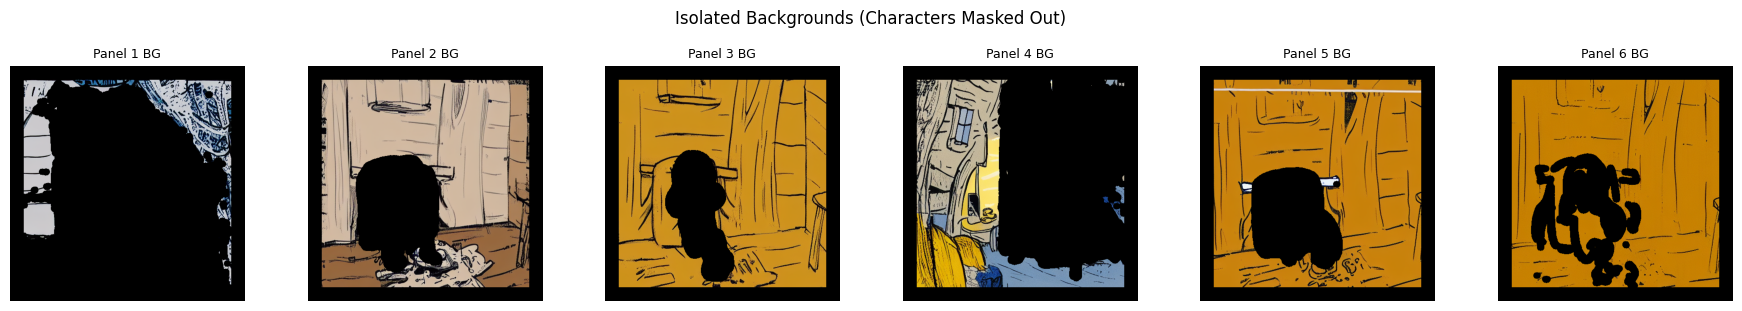

In [38]:
summary = bg_eval_results["summary"]

print("=" * 68)
print("             SCENE & BACKGROUND CONTINUITY REPORT (seq02)")
print("=" * 68)
if summary["mean_static_lpips"] is not None:
    print(f"Mean Static Masked LPIPS (lower=better):        {summary['mean_static_lpips']:.4f}")
if summary["mean_static_color_overlap"] is not None:
    print(f"Mean Static Color Overlap (higher=better):      {summary['mean_static_color_overlap']:.4f}")
if summary["mean_dynamic_reproj_error_px"] is not None:
    print(f"Mean Dynamic Homography Error (px, lower=better): {summary['mean_dynamic_reproj_error_px']:.2f} px")
if summary["mean_dynamic_inlier_ratio"] is not None:
    print(f"Mean Dynamic Inlier Ratio (higher=better):      {summary['mean_dynamic_inlier_ratio']:.4f}")
print("-" * 68)

for t in bg_eval_results["transitions"]:
    p1, p2 = t["pair"]
    print(f"Panel {p1} -> Panel {p2} [{t['type'].upper()}]:")
    if "static" in t:
        s = t["static"]
        lp = f"{s['lpips']:.4f}" if s["lpips"] is not None else "N/A"
        co = f"{s['color_overlap']:.4f}" if s["color_overlap"] is not None else "N/A"
        print(f"   Static  | LPIPS: {lp} | {s['color_space'].upper()} Overlap: {co} | Shared BG: {s['shared_bg_ratio']*100:.1f}%")
    if "dynamic" in t:
        d = t["dynamic"]
        err = f"{d['mean_reproj_error_px']:.2f} px" if d["mean_reproj_error_px"] is not None else "N/A"
        print(
            f"   Dynamic | Status: {d['status']} | BG Matches: {d['num_bg_matches']}/{d['total_matches']} "
            f"| Inliers: {d['num_inliers']} ({d['inlier_ratio']*100:.1f}%) | Reproj Err: {err}"
        )
print("=" * 68 + "\n")

# 1. Visualize Isolated Backgrounds (verify character masks + dilation)
bg_masks = bg_eval_results["bg_masks"]
fig, axes = plt.subplots(1, len(seq02_frames), figsize=(3 * len(seq02_frames), 3))
for i, (frame_img, bg_mask) in enumerate(zip(seq02_frames, bg_masks)):
    bg_only = np.array(frame_img).copy()
    bg_only[bg_mask <= 127] = 0
    axes[i].imshow(bg_only)
    axes[i].set_title(f"Panel {i+1} BG", fontsize=9)
    axes[i].axis("off")
plt.suptitle("Isolated Backgrounds (Characters Masked Out)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

# 2. Visualize SuperPoint + LightGlue Inlier Matches for Dynamic Transitions
dyn_transitions = [t for t in bg_eval_results["transitions"] if "dynamic" in t and t["dynamic"]["num_inliers"] > 0]
for t in dyn_transitions:
    p1, p2 = t["pair"]
    d = t["dynamic"]
    img1_np = np.array(seq02_frames[p1 - 1])
    img2_np = np.array(seq02_frames[p2 - 1])

    # Resize side-by-side canvas if heights differ
    h1, w1 = img1_np.shape[:2]
    h2, w2 = img2_np.shape[:2]
    canvas = np.zeros((max(h1, h2), w1 + w2, 3), dtype=np.uint8)
    canvas[:h1, :w1] = img1_np
    canvas[:h2, w1:w1 + w2] = img2_np

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.imshow(canvas)
    for (x0, y0), (x1, y1) in zip(d["inlier_pts0"], d["inlier_pts1"]):
        ax.plot([x0, x1 + w1], [y0, y1], color="lime", linewidth=0.8, alpha=0.7)
        ax.scatter([x0, x1 + w1], [y0, y1], color="yellow", s=10)
    ax.set_title(
        f"Panel {p1} -> Panel {p2} Background Inliers: {d['num_inliers']} | "
        f"Reproj Error: {d['mean_reproj_error_px']:.2f} px",
        fontsize=10,
    )
    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [39]:
import logging
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple, Union

import cv2
import lpips
import numpy as np
import torch
import torchvision.transforms as T
from PIL import Image

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("StoryboardAdherenceEvaluator")


class StoryboardAdherenceEvaluator:
    """
    Evaluates Storyboard Adherence by comparing generated panels against
    their corresponding original storyboard panels using:
      - Canny edge detection (Soft Edge F1 + Symmetric Chamfer Distance)
      - Perceptual loss via LPIPS (both RGB and structure-focused Grayscale)
    """

    def __init__(
        self,
        lpips_net: str = "vgg",            # 'vgg' (standard perceptual loss) or 'alex'
        eval_max_side: int = 512,          # Normalizes resolution so pixel distances are comparable
        border_margin_frac: float = 0.06,  # Crops outer drawn panel frames
        canny_low: int = 60,
        canny_high: int = 150,
        edge_tolerance_px: int = 3,        # Pixel tolerance radius for Soft Edge F1
        device: Optional[str] = None,
    ) -> None:
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.eval_max_side = eval_max_side
        self.border_margin_frac = border_margin_frac
        self.canny_low = canny_low
        self.canny_high = canny_high
        self.edge_tolerance_px = edge_tolerance_px

        logger.info(f"Loading LPIPS ({lpips_net}) for Storyboard Adherence on {self.device}...")
        self.lpips_fn = lpips.LPIPS(net=lpips_net).to(self.device).eval()

    @staticmethod
    def _to_pil(img: Union[str, Path, Image.Image]) -> Image.Image:
        if isinstance(img, (str, Path)):
            return Image.open(img).convert("RGB")
        return img.convert("RGB")

    def _prepare_pair(
        self,
        sb_img: Image.Image,
        gen_img: Image.Image,
    ) -> Tuple[Image.Image, Image.Image]:
        """Aligns resolution (preserving storyboard aspect ratio) and trims outer panel borders."""
        w, h = sb_img.size
        scale = self.eval_max_side / max(w, h)
        target_size = (max(16, int(round(w * scale))), max(16, int(round(h * scale))))

        sb_resized = sb_img.resize(target_size, Image.BILINEAR)
        gen_resized = gen_img.resize(target_size, Image.BILINEAR)

        if self.border_margin_frac > 0:
            tw, th = target_size
            mx = int(tw * self.border_margin_frac)
            my = int(th * self.border_margin_frac)
            crop_box = (mx, my, tw - mx, th - my)
            sb_resized = sb_resized.crop(crop_box)
            gen_resized = gen_resized.crop(crop_box)

        return sb_resized, gen_resized

    def _extract_edges(self, img: Image.Image) -> np.ndarray:
        """Extracts binary Canny edge map (0 or 255)."""
        gray = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)
        blurred = cv2.GaussianBlur(gray, (3, 3), 0)
        return cv2.Canny(blurred, self.canny_low, self.canny_high)

    def _compute_edge_metrics(
        self,
        edges_sb: np.ndarray,
        edges_gen: np.ndarray,
    ) -> Dict[str, Optional[float]]:
        """
        Computes:
          - Soft Edge Precision, Recall, and F1 (higher = better, 0 to 1)
          - Symmetric Chamfer Distance in pixels (lower = better)
        """
        sb_bin = edges_sb > 0
        gen_bin = edges_gen > 0

        n_sb = int(sb_bin.sum())
        n_gen = int(gen_bin.sum())

        if n_sb == 0 or n_gen == 0:
            return {
                "edge_f1": None,
                "edge_precision": None,
                "edge_recall": None,
                "chamfer_dist_px": None,
            }

        # 1. Soft Edge F1 using morphological dilation tolerance
        k = 2 * self.edge_tolerance_px + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
        sb_dilated = cv2.dilate(edges_sb, kernel, iterations=1) > 0
        gen_dilated = cv2.dilate(edges_gen, kernel, iterations=1) > 0

        precision = float((gen_bin & sb_dilated).sum() / n_gen)
        recall = float((sb_bin & gen_dilated).sum() / n_sb)
        f1 = float(2 * precision * recall / (precision + recall + 1e-8))

        # 2. Symmetric Chamfer Distance via Euclidean Distance Transform
        dt_to_sb = cv2.distanceTransform((~sb_bin).astype(np.uint8), cv2.DIST_L2, 5)
        dt_to_gen = cv2.distanceTransform((~gen_bin).astype(np.uint8), cv2.DIST_L2, 5)

        dist_gen_to_sb = float(dt_to_sb[gen_bin].mean())
        dist_sb_to_gen = float(dt_to_gen[sb_bin].mean())
        chamfer = 0.5 * (dist_gen_to_sb + dist_sb_to_gen)

        return {
            "edge_f1": f1,
            "edge_precision": precision,
            "edge_recall": recall,
            "chamfer_dist_px": chamfer,
        }

    @torch.no_grad()
    def _compute_lpips(
        self,
        sb_img: Image.Image,
        gen_img: Image.Image,
    ) -> Tuple[float, float]:
        """Computes both RGB LPIPS and grayscale (color-invariant) LPIPS."""
        def to_tensor(pil_img: Image.Image) -> torch.Tensor:
            return T.ToTensor()(pil_img).unsqueeze(0).to(self.device) * 2.0 - 1.0

        # RGB LPIPS
        lpips_rgb = float(self.lpips_fn(to_tensor(sb_img), to_tensor(gen_img)).item())

        # Grayscale LPIPS (replicated to 3 channels so colorization isn't penalized)
        sb_gray = sb_img.convert("L").convert("RGB")
        gen_gray = gen_img.convert("L").convert("RGB")
        lpips_gray = float(self.lpips_fn(to_tensor(sb_gray), to_tensor(gen_gray)).item())

        return lpips_rgb, lpips_gray

    def evaluate_pair(
        self,
        sb_img: Union[str, Path, Image.Image],
        gen_img: Union[str, Path, Image.Image],
    ) -> Dict[str, Any]:
        sb_prep, gen_prep = self._prepare_pair(self._to_pil(sb_img), self._to_pil(gen_img))

        edges_sb = self._extract_edges(sb_prep)
        edges_gen = self._extract_edges(gen_prep)

        edge_metrics = self._compute_edge_metrics(edges_sb, edges_gen)
        lpips_rgb, lpips_gray = self._compute_lpips(sb_prep, gen_prep)

        return {
            **edge_metrics,
            "lpips_rgb": lpips_rgb,
            "lpips_gray": lpips_gray,
            "sb_cropped": sb_prep,
            "gen_cropped": gen_prep,
            "edges_sb": edges_sb,
            "edges_gen": edges_gen,
        }

    def evaluate_sequence(
        self,
        storyboards: List[Optional[Union[str, Path, Image.Image]]],
        generated_frames: List[Optional[Union[str, Path, Image.Image]]],
    ) -> Dict[str, Any]:
        num_panels = min(len(storyboards), len(generated_frames))
        per_panel = []

        f1_list, chamfer_list, lpips_rgb_list, lpips_gray_list = [], [], [], []

        for idx in range(num_panels):
            sb, gen = storyboards[idx], generated_frames[idx]
            if sb is None or gen is None:
                logger.warning(f"Panel {idx+1}: Missing storyboard or generated frame. Skipping.")
                per_panel.append({"panel": idx + 1, "status": "missing"})
                continue

            res = self.evaluate_pair(sb, gen)
            res["panel"] = idx + 1
            res["status"] = "ok"
            per_panel.append(res)

            if res["edge_f1"] is not None:
                f1_list.append(res["edge_f1"])
            if res["chamfer_dist_px"] is not None:
                chamfer_list.append(res["chamfer_dist_px"])
            lpips_rgb_list.append(res["lpips_rgb"])
            lpips_gray_list.append(res["lpips_gray"])

        return {
            "per_panel": per_panel,
            "summary": {
                "mean_edge_f1": float(np.mean(f1_list)) if f1_list else None,
                "mean_chamfer_dist_px": float(np.mean(chamfer_list)) if chamfer_list else None,
                "mean_lpips_rgb": float(np.mean(lpips_rgb_list)) if lpips_rgb_list else None,
                "mean_lpips_gray": float(np.mean(lpips_gray_list)) if lpips_gray_list else None,
            },
        }

In [40]:
adherence_evaluator = StoryboardAdherenceEvaluator(
    lpips_net="vgg",
    eval_max_side=512,
    border_margin_frac=0.06,
    canny_low=60,
    canny_high=150,
    edge_tolerance_px=3,
)

adherence_results = adherence_evaluator.evaluate_sequence(
    storyboards=seq02_originals,
    generated_frames=seq02_frames,
)

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/vgg.pth


                 STORYBOARD ADHERENCE REPORT (seq02)
Mean Soft Edge F1 (higher=better, 0-1):         0.9796
Mean Edge Chamfer Distance (lower=better):      0.58 px
Mean Perceptual Loss - Grayscale LPIPS (lower): 0.4115
Mean Perceptual Loss - RGB LPIPS (lower):       0.5992
------------------------------------------------------------------------
Panel 1 | Edge F1: 0.9901 (P:0.99/R:0.99) | Chamfer: 0.56 px | LPIPS Gray: 0.3981 | RGB: 0.4358
Panel 2 | Edge F1: 0.9791 (P:0.97/R:0.98) | Chamfer: 0.65 px | LPIPS Gray: 0.3984 | RGB: 0.5128
Panel 3 | Edge F1: 0.9849 (P:0.98/R:0.99) | Chamfer: 0.49 px | LPIPS Gray: 0.3774 | RGB: 0.6495
Panel 4 | Edge F1: 0.9827 (P:0.99/R:0.97) | Chamfer: 0.66 px | LPIPS Gray: 0.3799 | RGB: 0.4439
Panel 5 | Edge F1: 0.9783 (P:0.97/R:0.99) | Chamfer: 0.50 px | LPIPS Gray: 0.4239 | RGB: 0.7333
Panel 6 | Edge F1: 0.9623 (P:0.98/R:0.95) | Chamfer: 0.62 px | LPIPS Gray: 0.4915 | RGB: 0.8203



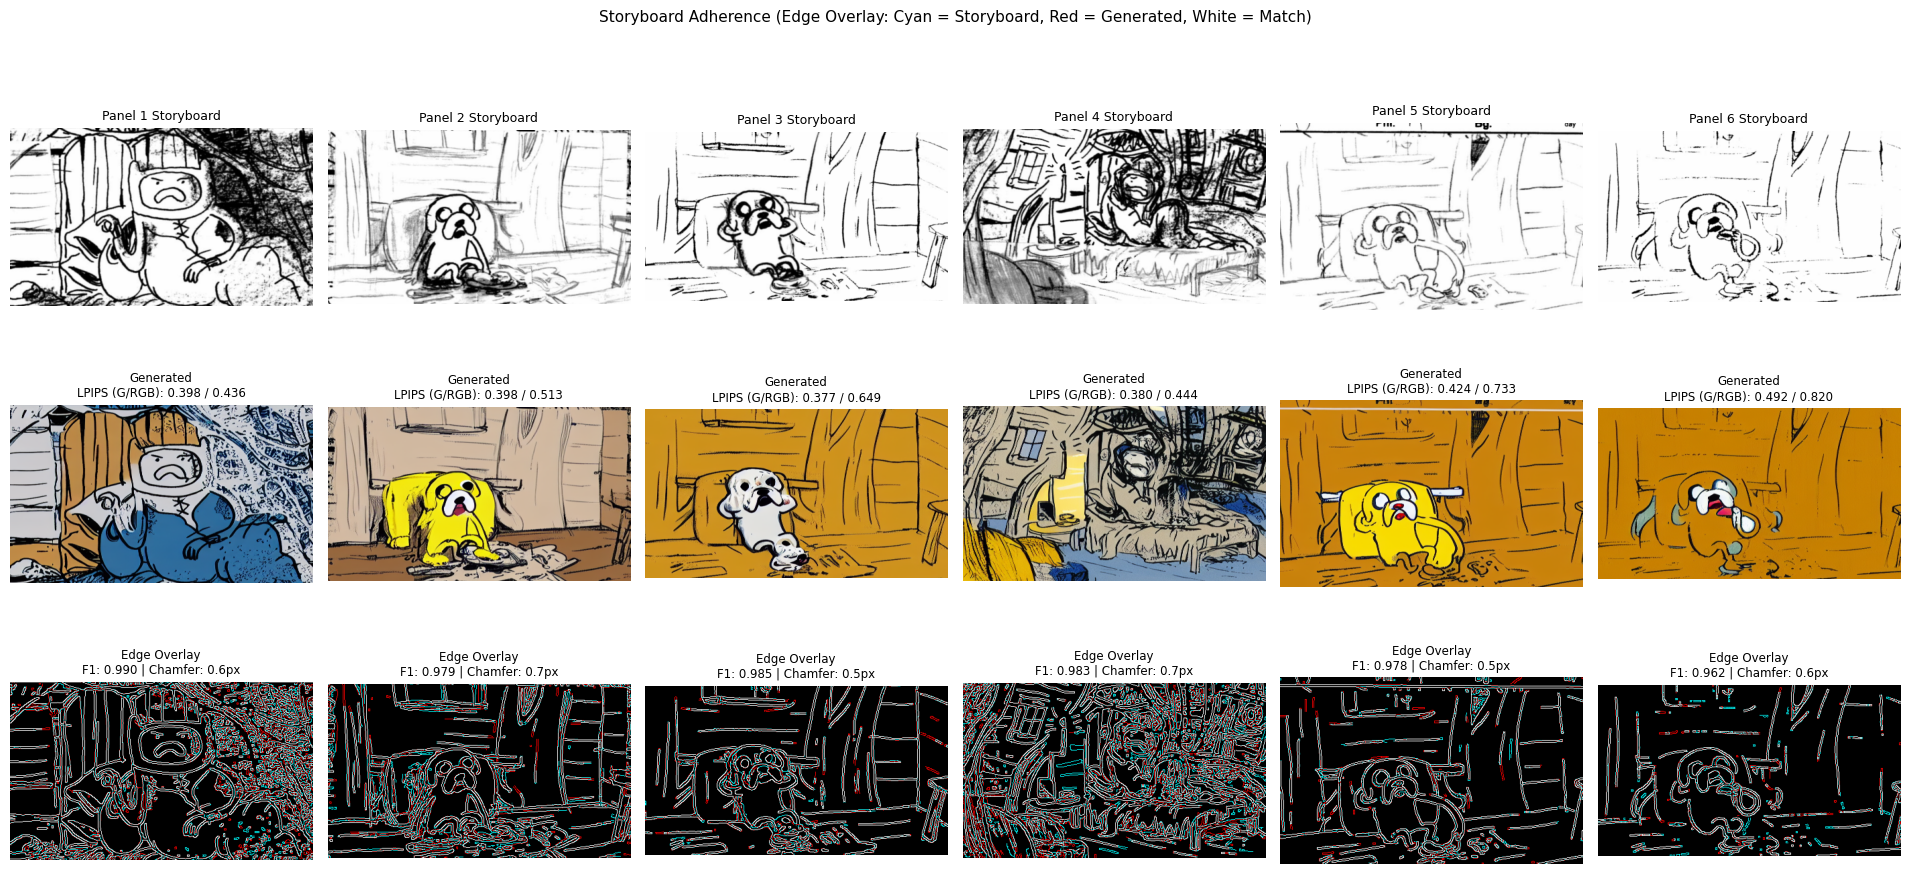

In [41]:
import matplotlib.pyplot as plt

summary = adherence_results["summary"]
per_panel = adherence_results["per_panel"]

print("=" * 72)
print("                 STORYBOARD ADHERENCE REPORT (seq02)")
print("=" * 72)
if summary["mean_edge_f1"] is not None:
    print(f"Mean Soft Edge F1 (higher=better, 0-1):         {summary['mean_edge_f1']:.4f}")
if summary["mean_chamfer_dist_px"] is not None:
    print(f"Mean Edge Chamfer Distance (lower=better):      {summary['mean_chamfer_dist_px']:.2f} px")
if summary["mean_lpips_gray"] is not None:
    print(f"Mean Perceptual Loss - Grayscale LPIPS (lower): {summary['mean_lpips_gray']:.4f}")
if summary["mean_lpips_rgb"] is not None:
    print(f"Mean Perceptual Loss - RGB LPIPS (lower):       {summary['mean_lpips_rgb']:.4f}")
print("-" * 72)

for p in per_panel:
    if p["status"] != "ok":
        print(f"Panel {p['panel']}: SKIPPED ({p['status']})")
        continue
    f1_str = f"{p['edge_f1']:.4f}" if p["edge_f1"] is not None else "N/A"
    ch_str = f"{p['chamfer_dist_px']:.2f} px" if p["chamfer_dist_px"] is not None else "N/A"
    print(
        f"Panel {p['panel']} | Edge F1: {f1_str} (P:{p['edge_precision']:.2f}/R:{p['edge_recall']:.2f}) "
        f"| Chamfer: {ch_str} | LPIPS Gray: {p['lpips_gray']:.4f} | RGB: {p['lpips_rgb']:.4f}"
    )
print("=" * 72 + "\n")

# Visualize: Row 1 = Storyboard, Row 2 = Generated, Row 3 = Edge Overlay (Cyan=SB, Red=Gen, White=Match)
valid_panels = [p for p in per_panel if p["status"] == "ok"]
n = len(valid_panels)

if n > 0:
    fig, axes = plt.subplots(3, n, figsize=(3.2 * n, 9.2))
    if n == 1:
        axes = axes.reshape(3, 1)

    for col, p in enumerate(valid_panels):
        # Row 0: Original Storyboard
        axes[0, col].imshow(p["sb_cropped"])
        axes[0, col].set_title(f"Panel {p['panel']} Storyboard", fontsize=9)
        axes[0, col].axis("off")

        # Row 1: Generated Frame
        axes[1, col].imshow(p["gen_cropped"])
        axes[1, col].set_title(
            f"Generated\nLPIPS (G/RGB): {p['lpips_gray']:.3f} / {p['lpips_rgb']:.3f}",
            fontsize=8.5,
        )
        axes[1, col].axis("off")

        # Row 2: Edge Overlap Map (Cyan = Storyboard, Red = Generated, White = Overlap)
        h, w = p["edges_sb"].shape
        overlay = np.zeros((h, w, 3), dtype=np.uint8)
        overlay[:, :, 0] = p["edges_gen"]  # Red = Generated edges
        overlay[:, :, 1] = p["edges_sb"]   # Green + Blue (Cyan) = Storyboard edges
        overlay[:, :, 2] = p["edges_sb"]

        f1_val = f"{p['edge_f1']:.3f}" if p["edge_f1"] is not None else "N/A"
        ch_val = f"{p['chamfer_dist_px']:.1f}px" if p["chamfer_dist_px"] is not None else "N/A"

        axes[2, col].imshow(overlay)
        axes[2, col].set_title(f"Edge Overlay\nF1: {f1_val} | Chamfer: {ch_val}", fontsize=8.5)
        axes[2, col].axis("off")

    plt.suptitle(
        "Storyboard Adherence (Edge Overlay: Cyan = Storyboard, Red = Generated, White = Match)",
        fontsize=11,
        y=1.01,
    )
    plt.tight_layout()
    plt.show()

In [42]:
import numpy as np
from IPython.display import display, Markdown


def _fmt(val, decimals=4, suffix=""):
    if val is None or (isinstance(val, float) and np.isnan(val)):
        return "N/A"
    return f"{val:.{decimals}f}{suffix}"


run_label = OUTPUT_DIR.name if "OUTPUT_DIR" in globals() else "Unknown Run"
seq_label = seq_name if "seq_name" in globals() else "Unknown Sequence"

md_lines = [
    f"## Quantitative Evaluation Summary — `{run_label}` / `{seq_label}`",
    "",
    "### Master Scorecard",
    "| Category | Metric | Value | Goal |",
    "| :--- | :--- | :---: | :--- |",
]

# ---------------------------------------------------------
# 1. Character Identity Stability (Aggregated Across Chars)
# ---------------------------------------------------------
char_rows = []
if "character_eval_results" in globals() and character_eval_results:
    ref_fids, consec_sims, global_sims = [], [], []
    any_drift = False

    for char_name, data in character_eval_results.items():
        res = data["results"]
        panels = data.get("mapped_panels", [])
        rf = res.get("mean_reference_fidelity")
        cs = res.get("mean_consecutive_similarity")
        gs = res.get("global_pairwise_similarity")
        drift = res.get("drift_detected", False)

        if rf is not None and rf > 0:
            ref_fids.append(rf)
        if cs is not None and cs > 0:
            consec_sims.append(cs)
        if gs is not None and gs > 0:
            global_sims.append(gs)
        any_drift = any_drift or drift

        char_rows.append(
            f"| {char_name} | {', '.join(map(str, panels))} | {_fmt(rf)} | {_fmt(cs)} | {_fmt(gs)} | {'Drift' if drift else 'Stable'} |"
        )

    md_lines.extend([
        f"| **Character Identity** | Mean Reference Fidelity (DINOv2) | **{_fmt(np.mean(ref_fids) if ref_fids else None)}** | Higher (0–1) |",
        f"| | Mean Consecutive Similarity (DINOv2) | **{_fmt(np.mean(consec_sims) if consec_sims else None)}** | Higher (0–1) |",
        f"| | Mean Global Pairwise Similarity (DINOv2) | **{_fmt(np.mean(global_sims) if global_sims else None)}** | Higher (0–1) |",
        f"| | Drift Alert (< threshold) | **{'Yes' if any_drift else 'No'}** | No |",
    ])
else:
    md_lines.append("| **Character Identity** | *Not run* | N/A | — |")

# ---------------------------------------------------------
# 2. Scene & Background Continuity
# ---------------------------------------------------------
bg_rows = []
if "bg_eval_results" in globals() and bg_eval_results:
    bg_sum = bg_eval_results.get("summary", {})
    md_lines.extend([
        f"| **Background Continuity** | Mean Static Masked LPIPS | **{_fmt(bg_sum.get('mean_static_lpips'))}** | Lower |",
        f"| | Mean Static Color Overlap | **{_fmt(bg_sum.get('mean_static_color_overlap'))}** | Higher (0–1) |",
        f"| | Mean Dynamic Homography Error | **{_fmt(bg_sum.get('mean_dynamic_reproj_error_px'), 2, ' px')}** | Lower |",
        f"| | Mean Dynamic Inlier Ratio | **{_fmt(bg_sum.get('mean_dynamic_inlier_ratio'))}** | Higher (0–1) |",
    ])

    for t in bg_eval_results.get("transitions", []):
        p1, p2 = t["pair"]
        t_type = t["type"].upper()
        s = t.get("static")
        d = t.get("dynamic")

        lpips_val = _fmt(s["lpips"]) if s else "—"
        color_val = f"{_fmt(s['color_overlap'])} ({s['color_space'].upper()})" if s else "—"
        if d:
            err_val = _fmt(d["mean_reproj_error_px"], 2, " px")
            match_val = f"{d['num_inliers']}/{d['num_bg_matches']} ({d['status']})"
        else:
            err_val, match_val = "—", "—"

        bg_rows.append(
            f"| Panel {p1} → {p2} | {t_type} | {lpips_val} | {color_val} | {err_val} | {match_val} |"
        )
else:
    md_lines.append("| **Background Continuity** | *Not run* | N/A | — |")

# ---------------------------------------------------------
# 3. Storyboard Adherence
# ---------------------------------------------------------
adh_rows = []
if "adherence_results" in globals() and adherence_results:
    adh_sum = adherence_results.get("summary", {})
    md_lines.extend([
        f"| **Storyboard Adherence** | Mean Soft Edge F1 | **{_fmt(adh_sum.get('mean_edge_f1'))}** | Higher (0–1) |",
        f"| | Mean Edge Chamfer Distance | **{_fmt(adh_sum.get('mean_chamfer_dist_px'), 2, ' px')}** | Lower |",
        f"| | Mean Grayscale LPIPS (Structure) | **{_fmt(adh_sum.get('mean_lpips_gray'))}** | Lower |",
        f"| | Mean RGB LPIPS (Full Appearance) | **{_fmt(adh_sum.get('mean_lpips_rgb'))}** | Lower |",
    ])

    for p in adherence_results.get("per_panel", []):
        if p.get("status") != "ok":
            adh_rows.append(f"| Panel {p['panel']} | *Skipped ({p.get('status')})* | — | — | — | — |")
        else:
            pr = f"{_fmt(p.get('edge_precision'), 2)} / {_fmt(p.get('edge_recall'), 2)}"
            adh_rows.append(
                f"| Panel {p['panel']} | {_fmt(p.get('edge_f1'))} | {pr} | {_fmt(p.get('chamfer_dist_px'), 2, ' px')} "
                f"| {_fmt(p.get('lpips_gray'))} | {_fmt(p.get('lpips_rgb'))} |"
            )
else:
    md_lines.append("| **Storyboard Adherence** | *Not run* | N/A | — |")

# ---------------------------------------------------------
# Detailed Breakdowns
# ---------------------------------------------------------
if char_rows:
    md_lines.extend([
        "",
        "### 1. Character Identity Breakdown",
        "| Character | Panels | Ref Fidelity | Consecutive Sim | Global Sim | Status |",
        "| :--- | :---: | :---: | :---: | :---: | :---: |",
        *char_rows,
    ])

if bg_rows:
    md_lines.extend([
        "",
        "### 2. Background Continuity Breakdown",
        "| Transition | Type | Masked LPIPS | Color Overlap | Homography Err | Inliers / BG Matches |",
        "| :--- | :---: | :---: | :---: | :---: | :--- |",
        *bg_rows,
    ])

if adh_rows:
    md_lines.extend([
        "",
        "### 3. Storyboard Adherence Breakdown",
        "| Panel | Soft Edge F1 | Prec / Rec | Chamfer Dist | LPIPS (Gray) | LPIPS (RGB) |",
        "| :--- | :---: | :---: | :---: | :---: | :---: |",
        *adh_rows,
    ])

display(Markdown("\n".join(md_lines)))

## Quantitative Evaluation Summary — `controlnet_batch_csa_off` / `seq02`

### Master Scorecard
| Category | Metric | Value | Goal |
| :--- | :--- | :---: | :--- |
| **Character Identity** | Mean Reference Fidelity (DINOv2) | **0.3909** | Higher (0–1) |
| | Mean Consecutive Similarity (DINOv2) | **0.4504** | Higher (0–1) |
| | Mean Global Pairwise Similarity (DINOv2) | **0.4721** | Higher (0–1) |
| | Drift Alert (< threshold) | **Yes** | No |
| **Background Continuity** | Mean Static Masked LPIPS | **0.5844** | Lower |
| | Mean Static Color Overlap | **0.4715** | Higher (0–1) |
| | Mean Dynamic Homography Error | **N/A** | Lower |
| | Mean Dynamic Inlier Ratio | **N/A** | Higher (0–1) |
| **Storyboard Adherence** | Mean Soft Edge F1 | **0.9796** | Higher (0–1) |
| | Mean Edge Chamfer Distance | **0.58 px** | Lower |
| | Mean Grayscale LPIPS (Structure) | **0.4115** | Lower |
| | Mean RGB LPIPS (Full Appearance) | **0.5992** | Lower |

### 1. Character Identity Breakdown
| Character | Panels | Ref Fidelity | Consecutive Sim | Global Sim | Status |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Finn | 1, 4 | 0.3659 | 0.4501 | 0.4501 | Drift |
| Jake | 2, 3, 4, 5, 6 | 0.4158 | 0.4507 | 0.4941 | Drift |

### 2. Background Continuity Breakdown
| Transition | Type | Masked LPIPS | Color Overlap | Homography Err | Inliers / BG Matches |
| :--- | :---: | :---: | :---: | :---: | :--- |
| Panel 1 → 2 | DYNAMIC | — | — | N/A | 0/3 (insufficient_matches) |
| Panel 2 → 3 | STATIC | 0.6829 | 0.0844 (LAB) | — | — |
| Panel 3 → 4 | DYNAMIC | — | — | N/A | 0/3 (insufficient_matches) |
| Panel 4 → 5 | DYNAMIC | — | — | N/A | 0/1 (insufficient_matches) |
| Panel 5 → 6 | STATIC | 0.4858 | 0.8585 (LAB) | — | — |

### 3. Storyboard Adherence Breakdown
| Panel | Soft Edge F1 | Prec / Rec | Chamfer Dist | LPIPS (Gray) | LPIPS (RGB) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Panel 1 | 0.9901 | 0.99 / 0.99 | 0.56 px | 0.3981 | 0.4358 |
| Panel 2 | 0.9791 | 0.97 / 0.98 | 0.65 px | 0.3984 | 0.5128 |
| Panel 3 | 0.9849 | 0.98 / 0.99 | 0.49 px | 0.3774 | 0.6495 |
| Panel 4 | 0.9827 | 0.99 / 0.97 | 0.66 px | 0.3799 | 0.4439 |
| Panel 5 | 0.9783 | 0.97 / 0.99 | 0.50 px | 0.4239 | 0.7333 |
| Panel 6 | 0.9623 | 0.98 / 0.95 | 0.62 px | 0.4915 | 0.8203 |